In [19]:
import pandas as pd 
from pathlib import Path

print(Path.cwd())

data_train = pd.read_csv("../data/train.csv")
data_train.head()
data_train.shape
data_train.info()


c:\Users\danie\OneDrive\Desktop\Proyectos\Proyecto Credito Fraude\Kaggle-Fraud-Detection\notebooks
<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week     

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [21]:
data_train.isna().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [26]:
proporcion = data_train["is_fraud"].value_counts(dropna=False)
print(proporcion)
porporcion_porcentaje = data_train["is_fraud"].value_counts(normalize=True) * 100
print(porporcion_porcentaje)

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64
is_fraud
0.0    98.330047
1.0     1.669953
Name: proportion, dtype: float64


Porcentaje de fraude = 1.66%
Porcentaje de No fraude = 98.33%

Clase minoritaria = fraude
Clase mayoritaria = nofraude

Acertar siempre en la clase mayoritaria no tendria sentido porque el objetivo es que nuestro modelo identifique los fraudes

##Calidad de los resultados

In [30]:
data_train.duplicated().sum()
data_train["id"].duplicated().sum()

np.int64(0)

In [31]:
data_train.drop(columns=["id"]).duplicated().sum()

np.int64(0)

In [32]:
data_train.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


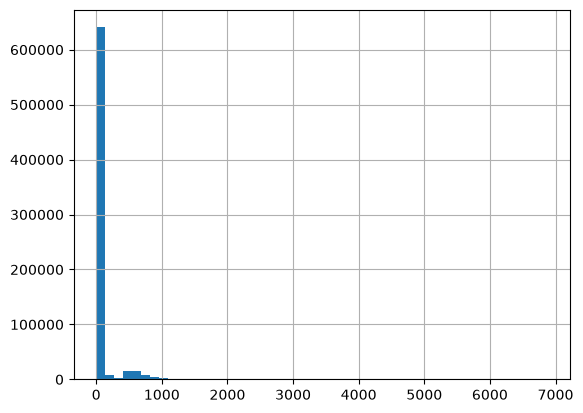

In [33]:
import matplotlib.pyplot as plt

data_train["amount_usd"].hist(bins=50)
plt.show()

<Axes: >

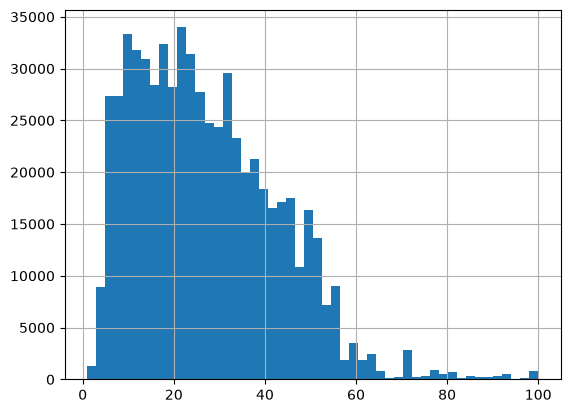

In [35]:
#Distribucion de montos hasta 100

data_train.loc[data_train["amount_usd"] <= 100, "amount_usd"].hist(bins=50)

In [36]:
data_train.groupby("is_fraud")["amount_usd"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0.0,688271.0,79.373189,204.165806,1.0,15.77,27.21,42.95,6872.69
1.0,11689.0,110.504532,255.808218,1.0,16.77,31.18,49.89,6078.29


In [42]:
rangos_montos = pd.cut(
    data_train["amount_usd"],
    bins=[0, 20, 50, 100, float("inf")],
    include_lowest=True
)
print(rangos_montos)

data_train.groupby(rangos_montos, observed=True)["is_fraud"].agg(["count", "sum", "mean"])

0          (50.0, 100.0]
1           (20.0, 50.0]
2         (-0.001, 20.0]
3           (20.0, 50.0]
4           (100.0, inf]
               ...      
699955      (100.0, inf]
699956      (20.0, 50.0]
699957      (20.0, 50.0]
699958    (-0.001, 20.0]
699959      (20.0, 50.0]
Name: amount_usd, Length: 699960, dtype: category
Categories (4, interval[float64, right]): [(-0.001, 20.0] < (20.0, 50.0] < (50.0, 100.0] < (100.0, inf]]


,count,sum,mean
amount_usd,,,
"(-0.001, 20.0]",239329,3631.0,0.015172
"(20.0, 50.0]",338891,5159.0,0.015223
"(50.0, 100.0]",53605,930.0,0.017349
"(100.0, inf]",68135,1969.0,0.028899


In [44]:
resumen_montos = (
    data_train.groupby(rangos_montos, observed=True)["is_fraud"]
    .agg(["count", "sum", "mean"])
)

resumen_montos["fraud_percentage"] = resumen_montos["mean"] * 100

resumen_montos

,count,sum,mean,fraud_percentage
amount_usd,,,,
"(-0.001, 20.0]",239329,3631.0,0.015172,1.517158
"(20.0, 50.0]",338891,5159.0,0.015223,1.522318
"(50.0, 100.0]",53605,930.0,0.017349,1.734913
"(100.0, inf]",68135,1969.0,0.028899,2.889851


In [51]:
canales = data_train["channel"]

resumen_channel = (
    data_train.groupby(canales, observed=True)["is_fraud"]
    .agg(["count", "sum", "mean"])
)

resumen_channel["fraud_percentage"] = resumen_channel["mean"] * 100

resumen_channel

,count,sum,mean,fraud_percentage
channel,,,,
ATM,30220,480.0,0.015884,1.588352
Contactless,105620,1641.0,0.015537,1.553683
In-App,83716,1367.0,0.016329,1.632902
Online,273939,4773.0,0.017424,1.742359
POS,206465,3428.0,0.016603,1.660330


In [52]:
origen_pago = data_train["is_foreign_transaction"]
resumen_origen_pago = (data_train.groupby(origen_pago, observed = True)["is_fraud"]).agg(["count", "sum", "mean"])
resumen_origen_pago["fraud_percentage"] =resumen_origen_pago["mean"] * 100

resumen_origen_pago

,count,sum,mean,fraud_percentage
is_foreign_transaction,,,,
False,687862,10168.0,0.014782,1.478203
True,12098,1521.0,0.125723,12.572326


In [65]:
fraude_dia = data_train["day_of_week"].value_counts().sort_index()
fraude_dia = data_train.groupby("day_of_week")["is_fraud"].agg(["count", "sum", "mean"])
fraude_dia["fraud_percentage"] = fraude_dia["mean"] * 100
fraude_dia

,count,sum,mean,fraud_percentage
day_of_week,,,,
0,100548,1591.0,0.015823,1.582329
1,102288,1694.0,0.016561,1.656108
2,101467,1697.0,0.016725,1.672465
3,97261,1595.0,0.016399,1.639917
4,102508,1718.0,0.016760,1.675967
5,95271,1600.0,0.016794,1.679420
6,100617,1794.0,0.017830,1.782999


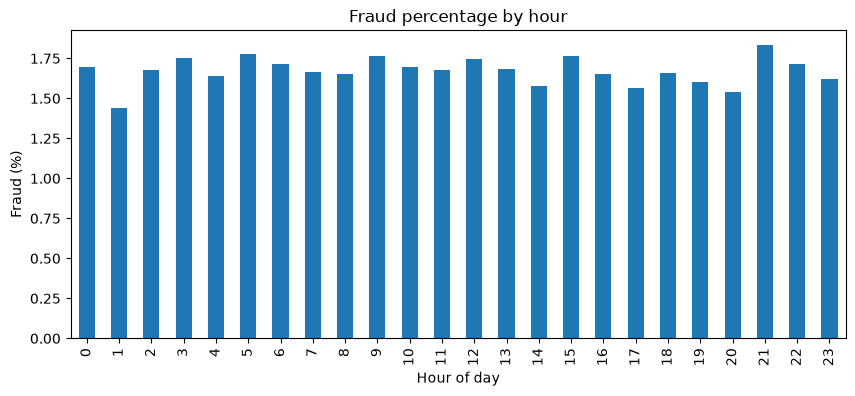

In [68]:
fraude_hora = data_train["time_of_day_hour"].value_counts().sort_index()
fraude_hora = data_train.groupby("time_of_day_hour")["is_fraud"].agg(["count", "sum", "mean"])
fraude_hora["fraud_percentage"] = fraude_hora["mean"] * 100
fraude_hora

fraude_hora["fraud_percentage"].plot(
    kind="bar",
    figsize=(10, 4)
)

plt.xlabel("Hour of day")
plt.ylabel("Fraud (%)")
plt.title("Fraud percentage by hour")
plt.ylim(bottom=0)
plt.show()

In [69]:
data_train.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

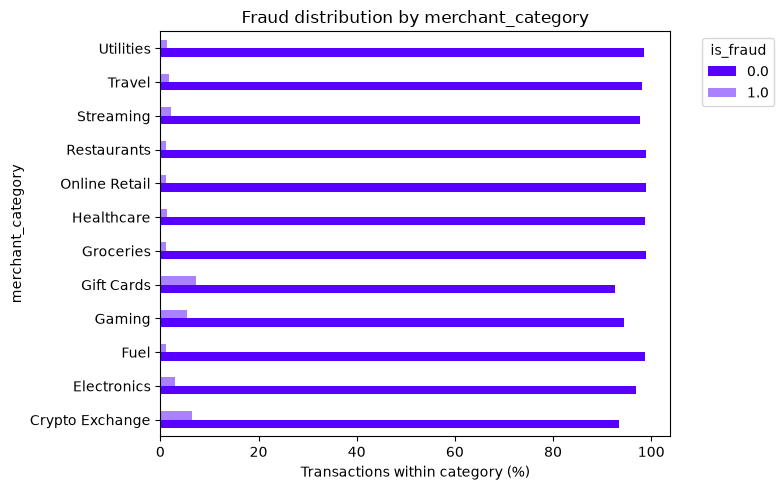

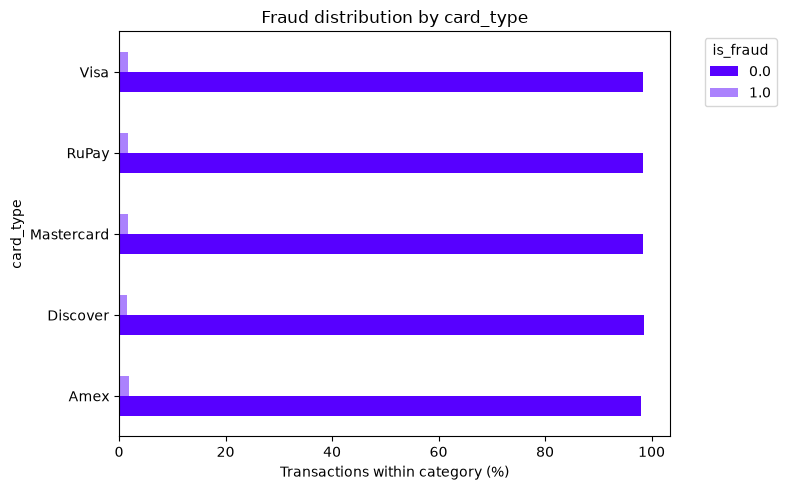

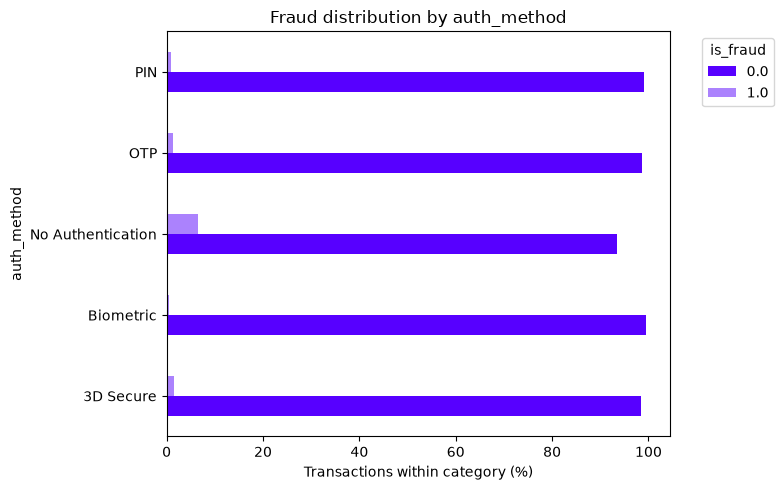

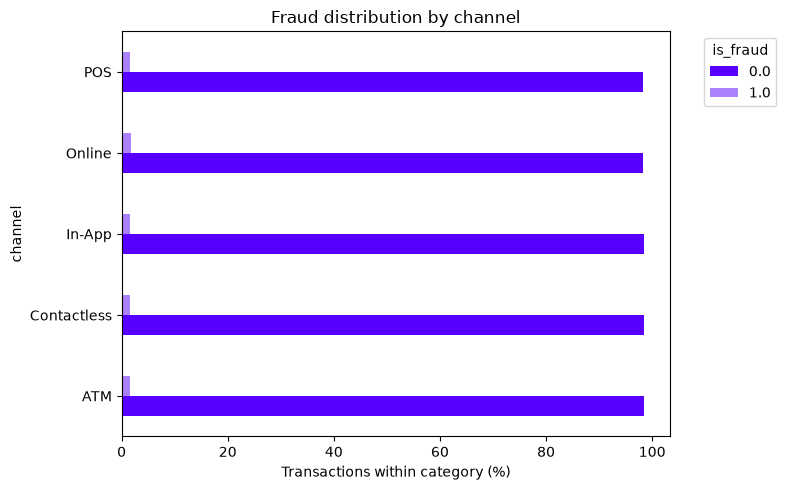

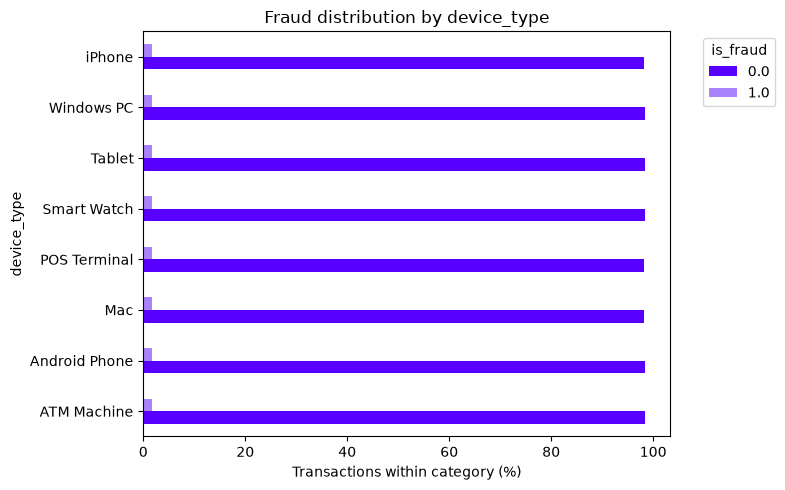

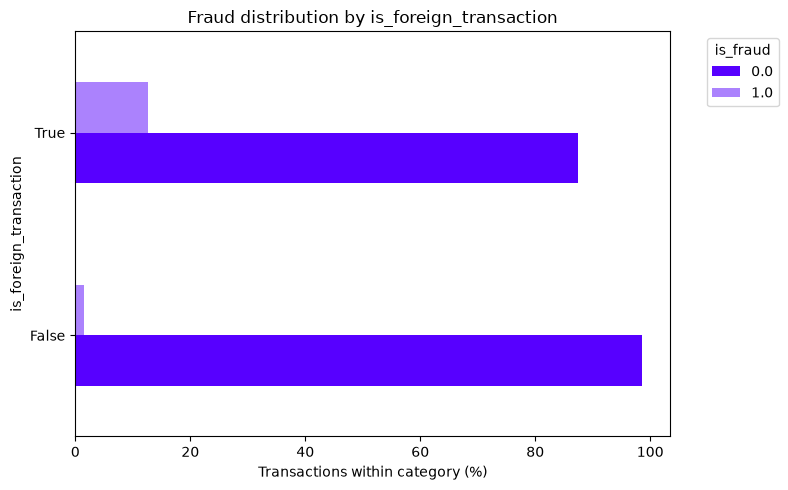

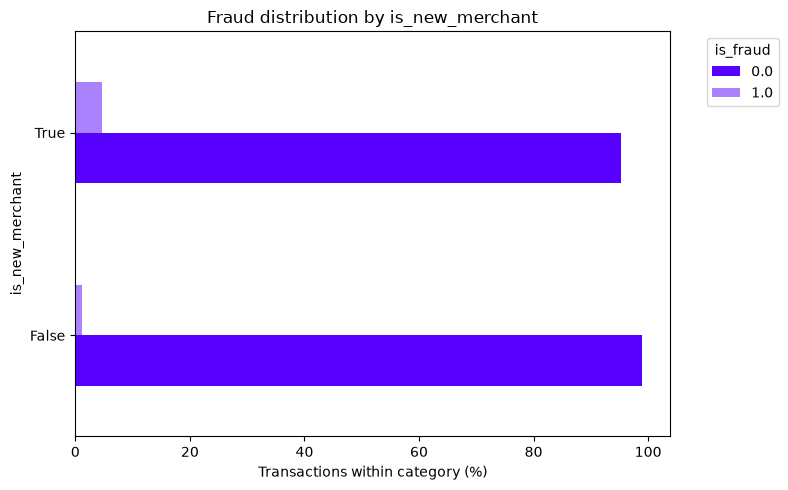

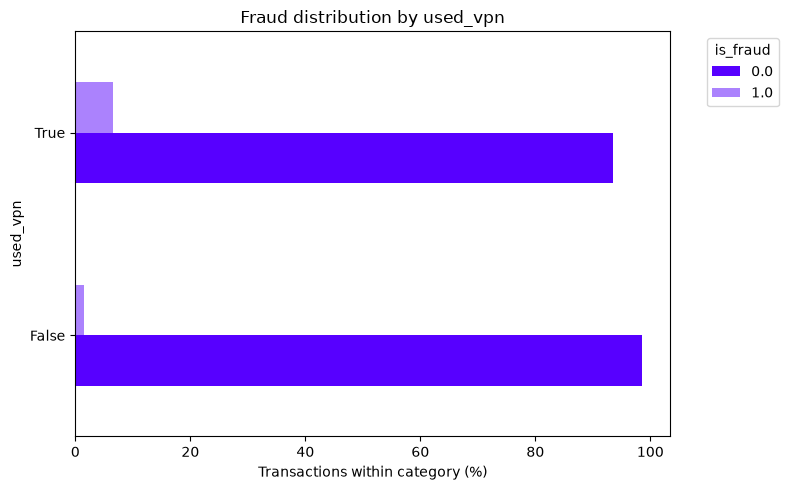

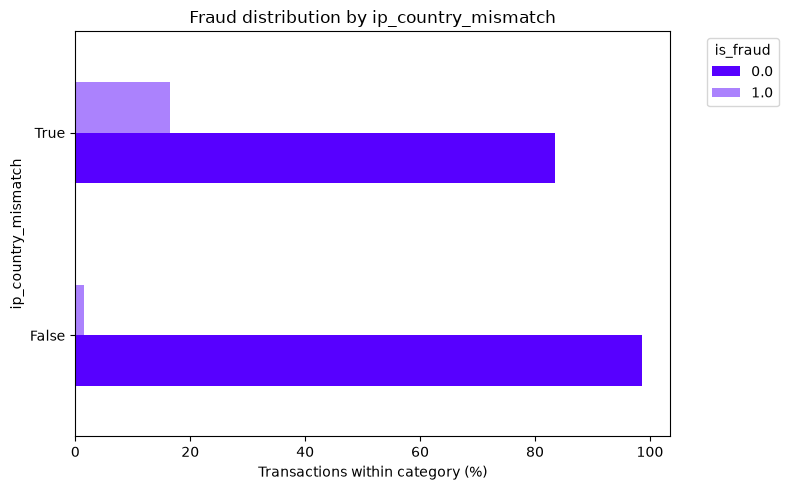

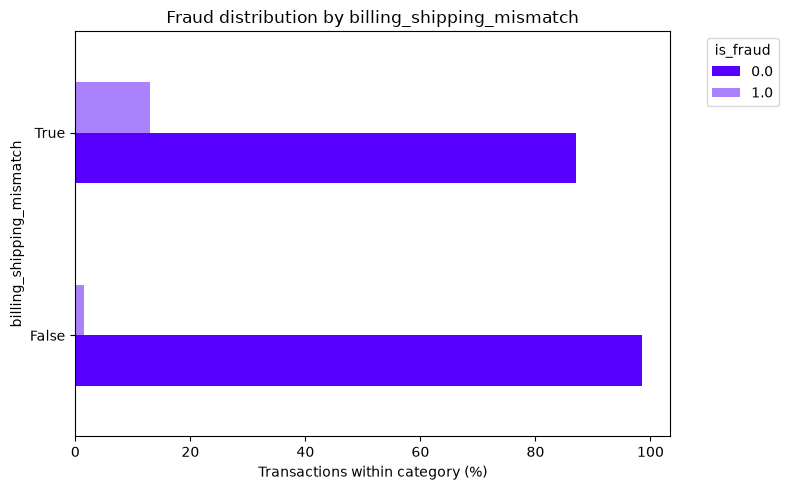

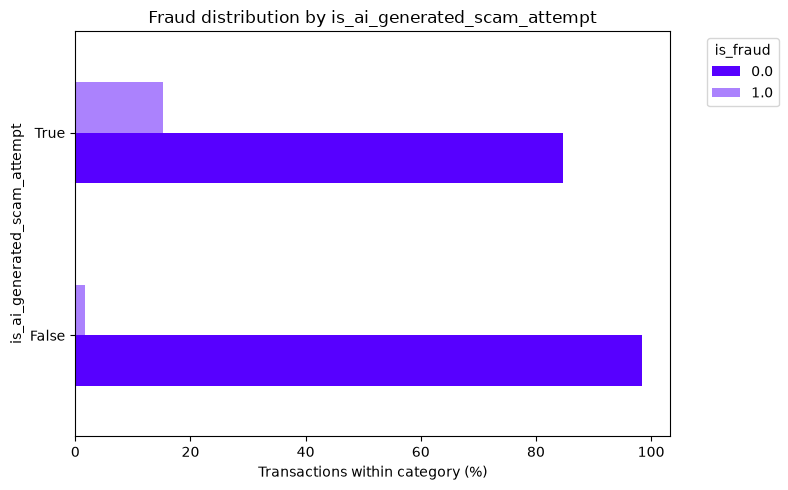

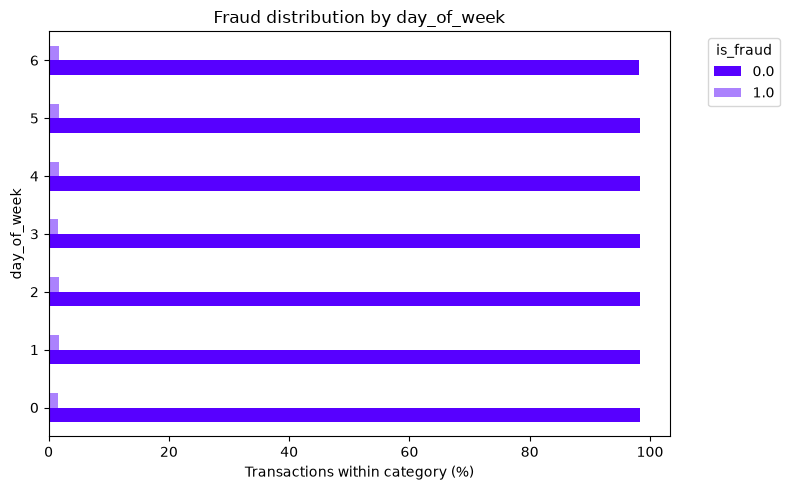

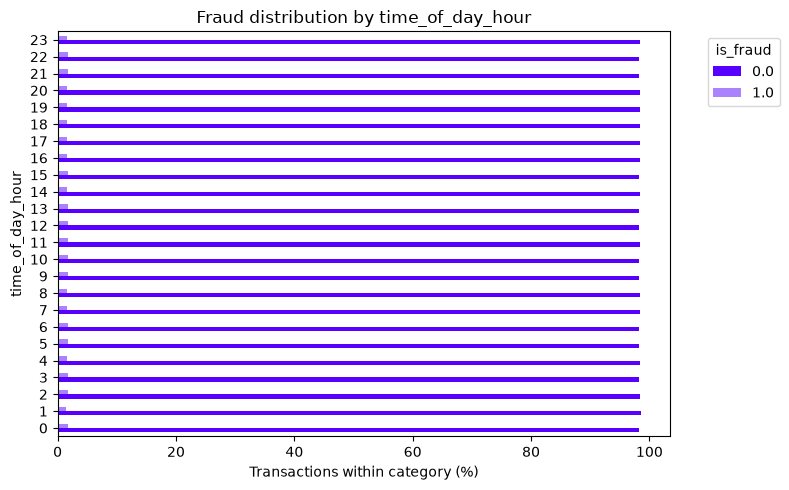

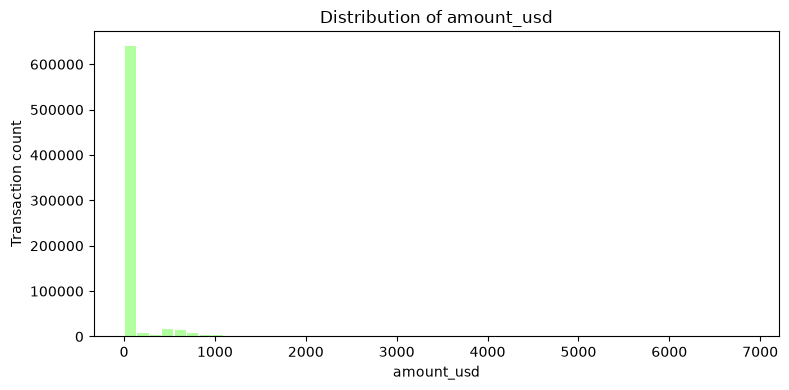

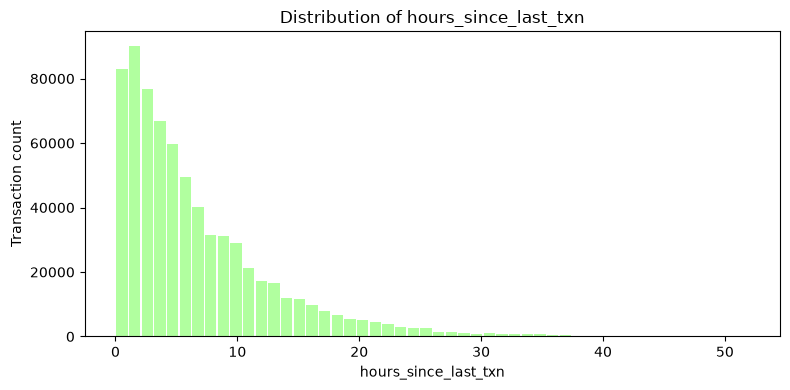

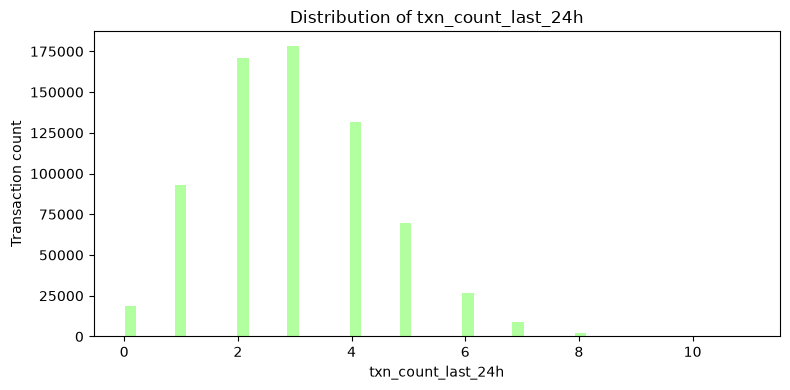

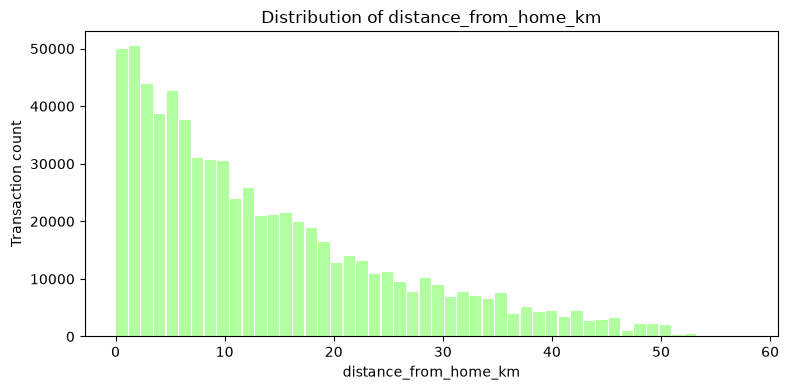

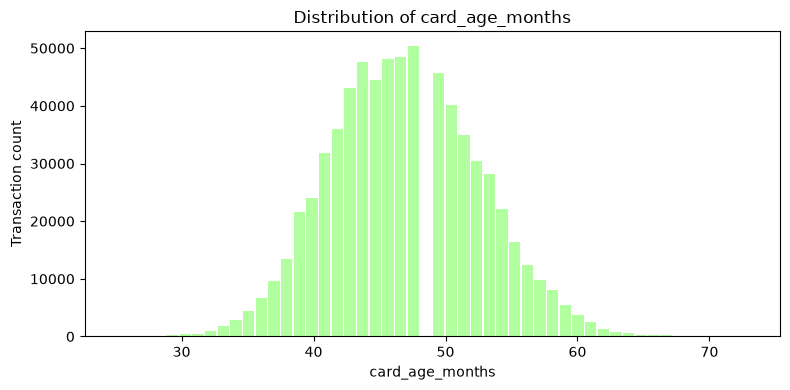

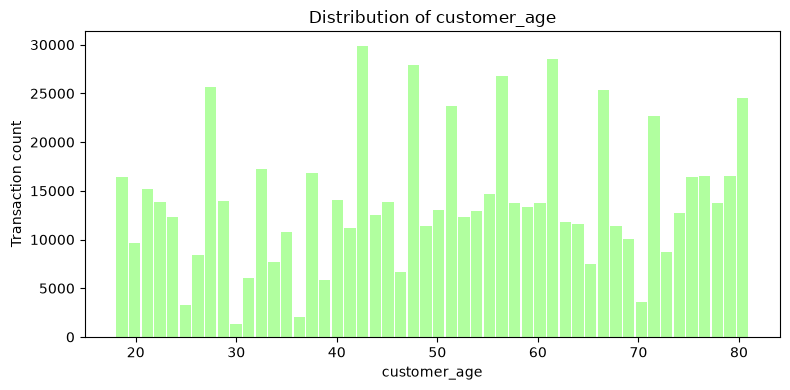

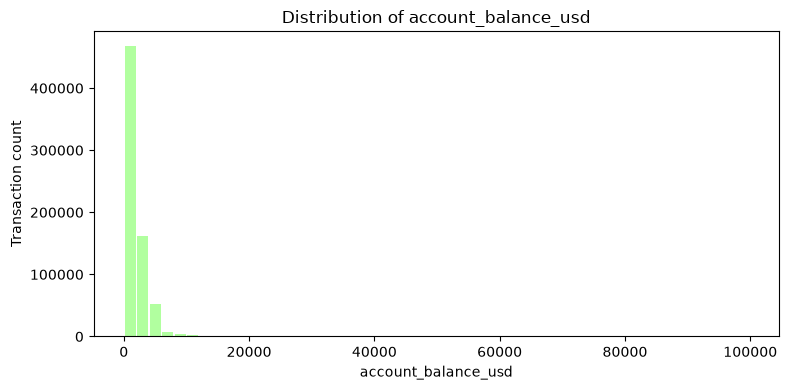

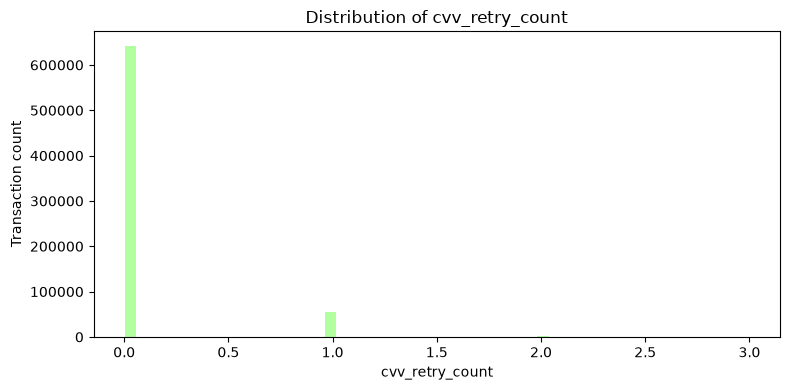

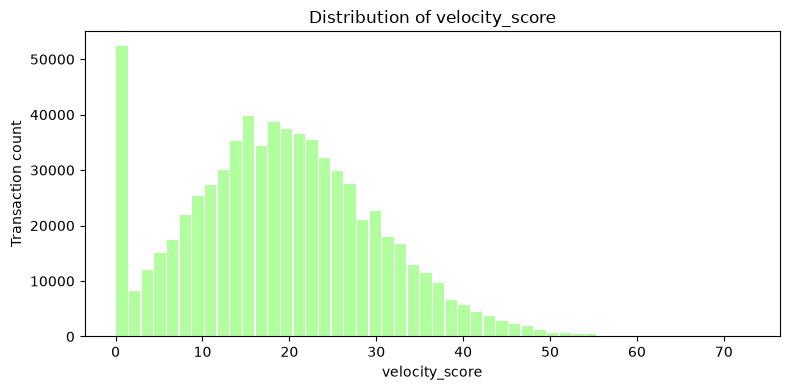

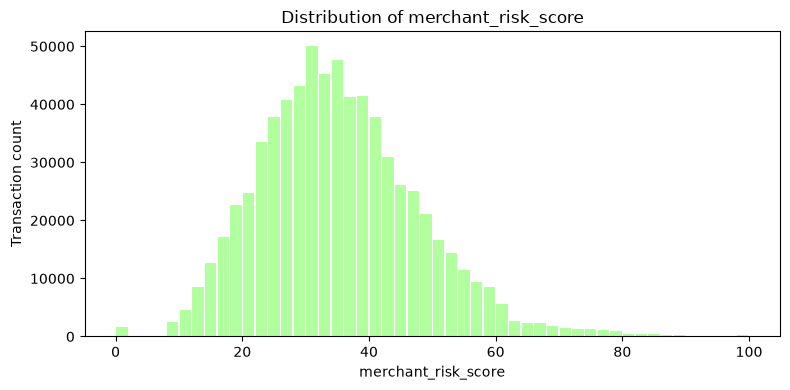

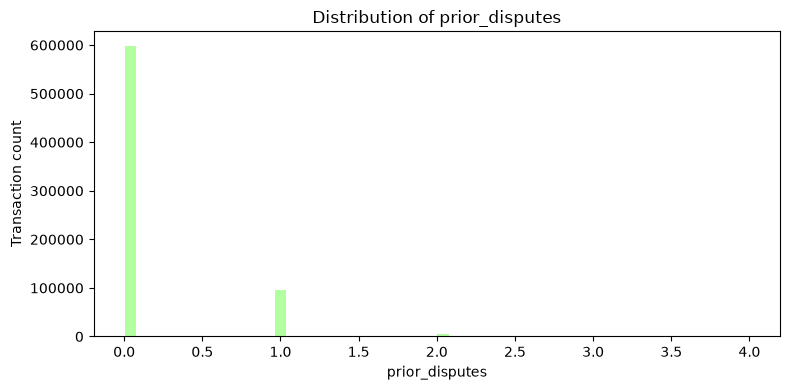

In [72]:
categoricas = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type",
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
    "day_of_week",
    "time_of_day_hour",
]

numericas = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "merchant_risk_score",
    "prior_disputes",
]

ordinales = []

import matplotlib.pyplot as plt

for columna in categoricas:
    tabla = pd.crosstab(
        data_train[columna],
        data_train["is_fraud"],
        normalize="index",
    ) * 100

    tabla.plot(
        kind="barh",
        color=["#5700ff", "#ab82fd"],
        figsize=(8, 5),
    )

    plt.title(f"Fraud distribution by {columna}")
    plt.xlabel("Transactions within category (%)")
    plt.ylabel(columna)
    plt.legend(
        title="is_fraud",
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
    )
    plt.tight_layout()
    plt.show()


for columna in numericas:
    plt.figure(figsize=(8, 4))

    plt.hist(
        data_train[columna],
        bins=50,
        color="#b1ff9f",
        rwidth=0.9,
    )

    plt.title(f"Distribution of {columna}")
    plt.xlabel(columna)
    plt.ylabel("Transaction count")
    plt.tight_layout()
    plt.show()

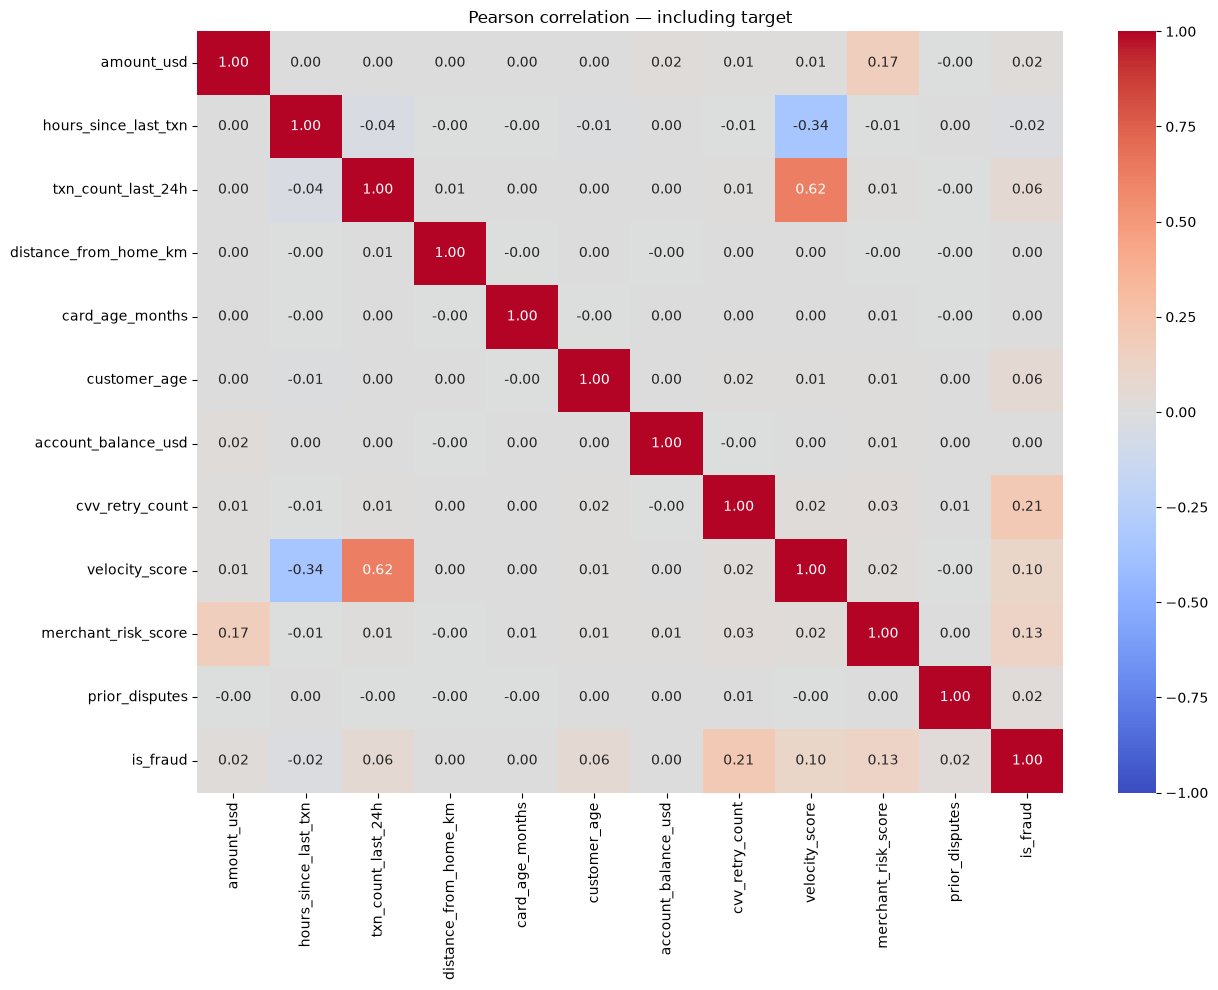


Pearson correlation with is_fraud:
cvv_retry_count          0.212290
merchant_risk_score      0.125391
velocity_score           0.101650
txn_count_last_24h       0.058035
customer_age             0.056051
prior_disputes           0.023644
amount_usd               0.019443
distance_from_home_km    0.001826
account_balance_usd      0.001077
card_age_months          0.000681
hours_since_last_txn    -0.020490
Name: is_fraud, dtype: float64


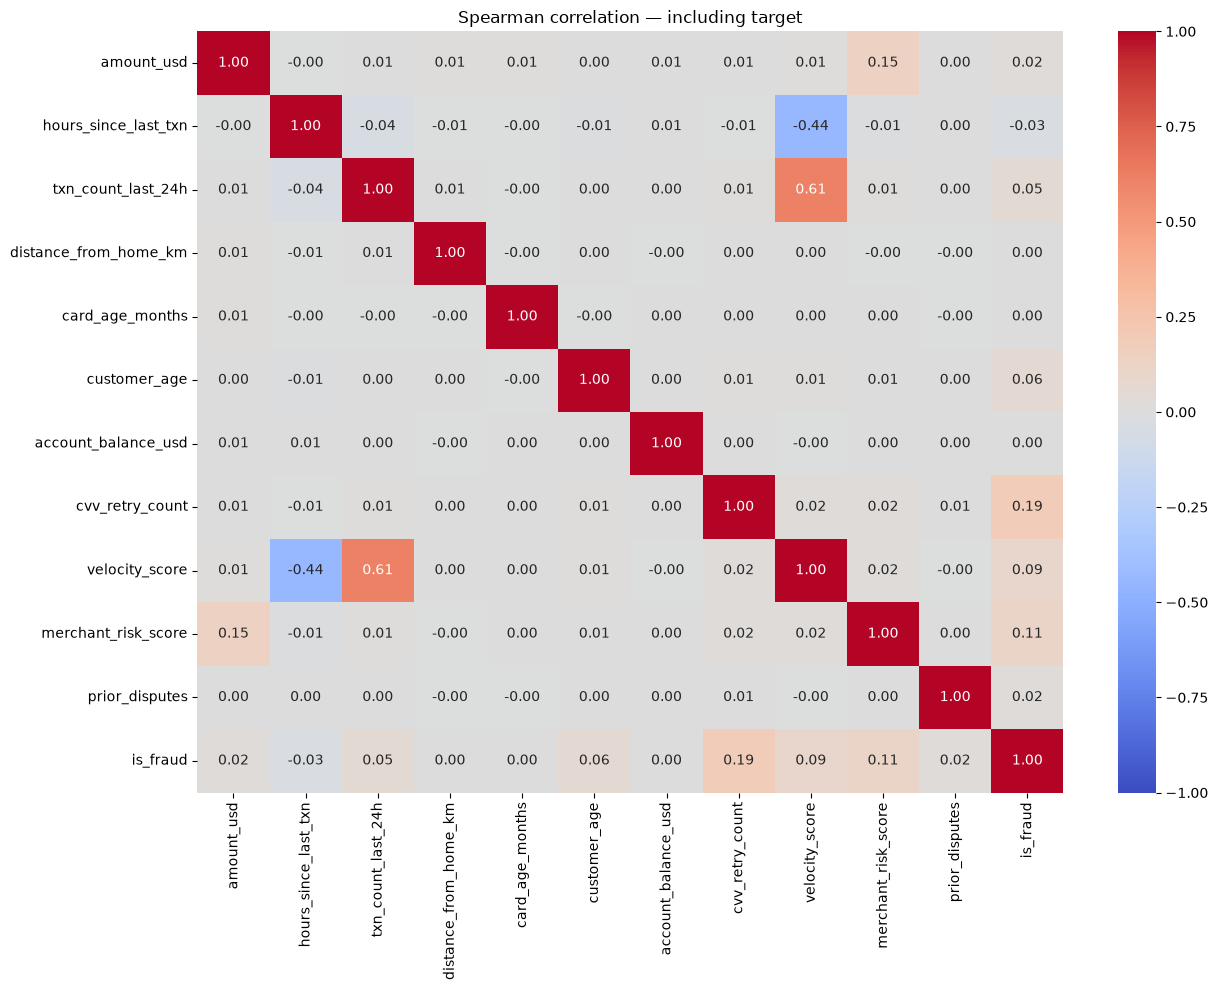


Spearman correlation with is_fraud:
cvv_retry_count          0.193620
merchant_risk_score      0.110503
velocity_score           0.093587
customer_age             0.055374
txn_count_last_24h       0.054539
prior_disputes           0.023400
amount_usd               0.019909
account_balance_usd      0.002776
distance_from_home_km    0.001719
card_age_months          0.000849
hours_since_last_txn    -0.030284
Name: is_fraud, dtype: float64


In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

columnas_correlacion = numericas + ["is_fraud"]
correlaciones = {}

for metodo in ["pearson", "spearman"]:
    matriz = data_train[columnas_correlacion].corr(method=metodo)
    correlaciones[metodo] = matriz

    plt.figure(figsize=(13, 10))
    sns.heatmap(
        matriz,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
    )

    plt.title(f"{metodo.capitalize()} correlation — including target")
    plt.tight_layout()
    plt.show()

    # Exclude the target's correlation with itself.
    correlacion_target = (
        matriz["is_fraud"]
        .drop("is_fraud")
        .sort_values(ascending=False)
    )

    print(f"\n{metodo.capitalize()} correlation with is_fraud:")
    print(correlacion_target)

In [79]:
tabla_iv = (
    data_train.groupby("is_foreign_transaction")["is_fraud"]
    .agg(total="count", fraud="sum")
)

tabla_iv["non_fraud"] = tabla_iv["total"] - tabla_iv["fraud"]

tabla_iv

,total,fraud,non_fraud
is_foreign_transaction,,,
False,687862,10168.0,677694.0
True,12098,1521.0,10577.0


In [80]:
import numpy as np

# Count fraud and non-fraud transactions in each group.
tabla_iv = (
    data_train.groupby("is_foreign_transaction", dropna=False)["is_fraud"]
    .agg(total="count", fraud="sum")
)

tabla_iv["non_fraud"] = tabla_iv["total"] - tabla_iv["fraud"]

# Apply smoothing only if a group has zero observations of either class.
if (tabla_iv[["fraud", "non_fraud"]].sum() == 0).any():
    raise ValueError("IV requires both target classes.")

smoothing = (
    0.5
    if (tabla_iv[["fraud", "non_fraud"]] == 0).any().any()
    else 0.0
)

n_groups = len(tabla_iv)

tabla_iv["dist_fraud"] = (
    (tabla_iv["fraud"] + smoothing)
    / (tabla_iv["fraud"].sum() + smoothing * n_groups)
)

tabla_iv["dist_non_fraud"] = (
    (tabla_iv["non_fraud"] + smoothing)
    / (tabla_iv["non_fraud"].sum() + smoothing * n_groups)
)

# Calculate Weight of Evidence and each group's IV contribution.
tabla_iv["woe"] = np.log(
    tabla_iv["dist_non_fraud"] / tabla_iv["dist_fraud"]
)

tabla_iv["iv_contribution"] = (
    tabla_iv["dist_non_fraud"] - tabla_iv["dist_fraud"]
) * tabla_iv["woe"]

iv_total = tabla_iv["iv_contribution"].sum()

print(f"IV — is_foreign_transaction: {iv_total:.4f}")
tabla_iv

IV — is_foreign_transaction: 0.2594


,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
is_foreign_transaction,,,,,,,
False,687862,10168.0,677694.0,0.869878,0.984633,0.123916,0.014220
True,12098,1521.0,10577.0,0.130122,0.015367,-2.136221,0.245142


##is_foreign_transaction presenta un IV exploratorio de 0,2594. La separación proviene principalmente del grupo marcado como extranjero, más representado entre los fraudes que entre los no fraudes.

In [82]:
import numpy as np

# Count fraud and non-fraud transactions in each group.
tabla_iv = (
    data_train.groupby("used_vpn", dropna=False)["is_fraud"]
    .agg(total="count", fraud="sum")
)

tabla_iv["non_fraud"] = tabla_iv["total"] - tabla_iv["fraud"]

# Apply smoothing only if a group has zero observations of either class.
if (tabla_iv[["fraud", "non_fraud"]].sum() == 0).any():
    raise ValueError("IV requires both target classes.")

smoothing = (
    0.5
    if (tabla_iv[["fraud", "non_fraud"]] == 0).any().any()
    else 0.0
)

n_groups = len(tabla_iv)

tabla_iv["dist_fraud"] = (
    (tabla_iv["fraud"] + smoothing)
    / (tabla_iv["fraud"].sum() + smoothing * n_groups)
)

tabla_iv["dist_non_fraud"] = (
    (tabla_iv["non_fraud"] + smoothing)
    / (tabla_iv["non_fraud"].sum() + smoothing * n_groups)
)

# Calculate Weight of Evidence and each group's IV contribution.
tabla_iv["woe"] = np.log(
    tabla_iv["dist_non_fraud"] / tabla_iv["dist_fraud"]
)

tabla_iv["iv_contribution"] = (
    tabla_iv["dist_non_fraud"] - tabla_iv["dist_fraud"]
) * tabla_iv["woe"]

iv_total = tabla_iv["iv_contribution"].sum()
print(f"IV — used_vpn: {iv_total:.4f}")
tabla_iv

IV — used_vpn: 0.1534


,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
used_vpn,,,,,,,
False,676295,10139.0,666156.0,0.867397,0.967869,0.109600,0.011012
True,23665,1550.0,22115.0,0.132603,0.032131,-1.417533,0.142422


In [83]:
import numpy as np
import pandas as pd

def calcular_iv(grupos, target):
    datos = pd.DataFrame({"group": grupos, "target": target})

    tabla = (
        datos.groupby("group", observed=True, dropna=False)["target"]
        .agg(total="count", fraud="sum")
    )
    tabla["non_fraud"] = tabla["total"] - tabla["fraud"]

    if (tabla[["fraud", "non_fraud"]].sum() == 0).any():
        raise ValueError("IV requires both target classes.")

    smoothing = (
        0.5
        if (tabla[["fraud", "non_fraud"]] == 0).any().any()
        else 0.0
    )

    for clase in ["fraud", "non_fraud"]:
        tabla[f"dist_{clase}"] = (
            (tabla[clase] + smoothing)
            / (tabla[clase].sum() + smoothing * len(tabla))
        )

    tabla["woe"] = np.log(
        tabla["dist_non_fraud"] / tabla["dist_fraud"]
    )
    tabla["iv_contribution"] = (
        tabla["dist_non_fraud"] - tabla["dist_fraud"]
    ) * tabla["woe"]

    return tabla, smoothing


target = data_train["is_fraud"]

if target.isna().any() or set(target.unique()) != {0, 1}:
    raise ValueError("Target must contain both 0 and 1, without missing values.")

# Combine lists without repeating columns or including ID/target.
variables = [
    columna
    for columna in dict.fromkeys(categoricas + numericas)
    if columna not in ["id", "is_fraud"]
]

resultados = []
detalle_iv = {}

for columna in variables:
    serie = data_train[columna]

    if columna in numericas and serie.nunique() > 10:
        grupos = pd.qcut(serie, q=10, duplicates="drop")
        agrupacion = "Quantile bins"
    else:
        grupos = serie
        agrupacion = "Original values"

    tabla, smoothing = calcular_iv(grupos, target)
    detalle_iv[columna] = tabla

    resultados.append({
        "variable": columna,
        "iv": tabla["iv_contribution"].sum(),
        "groups": len(tabla),
        "min_group_count": tabla["total"].min(),
        "smoothing": smoothing,
        "grouping": agrupacion,
    })

resumen_iv = (
    pd.DataFrame(resultados)
    .sort_values("iv", ascending=False)
    .reset_index(drop=True)
)

resumen_iv

,variable,iv,groups,min_group_count,smoothing,grouping
0,cvv_retry_count,1.090394,4,25,0.0,Original values
1,merchant_risk_score,0.884425,10,69039,0.0,Quantile bins
2,velocity_score,0.688373,10,67562,0.0,Quantile bins
3,auth_method,0.588991,5,67060,0.0,Original values
4,is_new_merchant,0.420971,2,106720,0.0,Original values
5,ip_country_mismatch,0.381394,2,11312,0.0,Original values
6,merchant_category,0.335885,12,5285,0.0,Original values
7,customer_age,0.263156,10,61654,0.0,Quantile bins
8,is_foreign_transaction,0.259362,2,12098,0.0,Original values
9,txn_count_last_24h,0.208517,6,38099,0.0,Quantile bins


In [84]:
detalle_iv["cvv_retry_count"]

,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
group,,,,,,,
0,642088,5990.0,636098.0,0.512448,0.924197,0.589727,0.242820
1,55942,4895.0,51047.0,0.418770,0.074167,-1.731002,0.596508
2,1905,795.0,1110.0,0.068013,0.001613,-3.741761,0.248453
3,25,9.0,16.0,0.000770,0.000023,-3.500170,0.002614


La proporción observada de fraude aumenta marcadamente entre 0, 1 y 2 reintentos de CVV. El grupo de 3 reintentos contiene pocos registros, por lo que su estimación debe interpretarse con cautela.

La disponibilidad temporal de cvv_retry_count no está confirmada. Su uso operativo requiere comprobar que el conteo esté disponible al momento de predecir.

In [102]:

detalle_iv["merchant_risk_score"]["fraud_percentage"] = (
    detalle_iv["merchant_risk_score"]["fraud"]
    / detalle_iv["merchant_risk_score"]["total"]
    * 100
)
detalle_iv

{'merchant_category':                   total   fraud  non_fraud  dist_fraud  dist_non_fraud  \
 group                                                                    
 Crypto Exchange    5285   345.0     4940.0    0.029515        0.007177   
 Electronics       48693  1501.0    47192.0    0.128411        0.068566   
 Fuel              59880   741.0    59139.0    0.063393        0.085924   
 Gaming            23784  1311.0    22473.0    0.112157        0.032651   
 Gift Cards         9456   690.0     8766.0    0.059030        0.012736   
 Groceries        142578  1585.0   140993.0    0.135598        0.204851   
 Healthcare        35889   462.0    35427.0    0.039524        0.051472   
 Online Retail    155097  1719.0   153378.0    0.147061        0.222845   
 Restaurants      101360  1159.0   100201.0    0.099153        0.145584   
 Streaming         47196  1061.0    46135.0    0.090769        0.067030   
 Travel            28715   534.0    28181.0    0.045684        0.040945   
 Uti

Se observa una tendencia generalmente creciente en la proporción de fraude conforme aumenta merchant_risk_score. La variable presenta un IV exploratorio elevado, aunque se desconoce cómo se calcula el puntaje y si toda su información está disponible al predecir.

In [97]:
detalle_iv["velocity_score"]

,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
group,,,,,,,
"(-0.001, 4.1]",70275,83.0,70192.0,0.007101,0.101983,2.664615,2.528250e-01
"(4.1, 9.5]",70226,398.0,69828.0,0.034049,0.101454,1.091804,7.359317e-02
"(9.5, 13.2]",72298,489.0,71809.0,0.041834,0.104332,0.913868,5.711516e-02
"(13.2, 15.8]",67562,692.0,66870.0,0.059201,0.097156,0.495385,1.880262e-02
"(15.8, 18.6]",69775,1021.0,68754.0,0.087347,0.099894,0.134218,1.683994e-03
"(18.6, 21.4]",70934,989.0,69945.0,0.084609,0.101624,0.183236,3.117711e-03
"(21.4, 24.4]",71090,1190.0,69900.0,0.101805,0.101559,-0.002422,5.965166e-07
"(24.4, 28.0]",68463,1571.0,66892.0,0.134400,0.097188,-0.324167,1.206272e-02
"(28.0, 33.1]",69960,1606.0,68354.0,0.137394,0.099313,-0.324581,1.236053e-02


velocity_score presenta una asociación generalmente creciente con la proporción de fraude. El intervalo superior registra aproximadamente un 5,26 % de fraude, frente al 0,12 % del inferior. Se desconoce la construcción y disponibilidad temporal del puntaje.

In [98]:
detalle_iv["auth_method"]

,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
group,,,,,,,
3D Secure,210036,3098.0,206938.0,0.265036,0.300664,0.126128,0.004494
Biometric,93666,468.0,93198.0,0.040038,0.135409,1.218479,0.116208
No Authentication,67060,4322.0,62738.0,0.369749,0.091153,-1.400285,0.390114
OTP,175178,2464.0,172714.0,0.210796,0.250939,0.174317,0.006997
PIN,154020,1337.0,152683.0,0.114381,0.221836,0.662401,0.071178


La proporción de fraude varía según el método de autenticación. El grupo sin autenticación presenta la mayor tasa observada y la principal contribución al IV de la variable. Esta asociación no demuestra causalidad.



In [100]:
detalle_iv["is_new_merchant"]

,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
group,,,,,,,
False,593240,6637.0,586603.0,0.567799,0.852285,0.406154,0.115545
True,106720,5052.0,101668.0,0.432201,0.147715,-1.073606,0.305426


In [101]:
detalle_iv["ip_country_mismatch"]

,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
group,,,,,,,
False,688648,9823.0,678825.0,0.840363,0.986276,0.160102,0.023361
True,11312,1866.0,9446.0,0.159637,0.013724,-2.453740,0.358033


Si tiene vpn probablemente sea fraude, aunque no hay muchos casos en los que se use vpn

In [104]:
detalle_iv["merchant_category"]
tabla_categoria = detalle_iv["merchant_category"]

tabla_categoria["fraud_percentage"] = (
    tabla_categoria["fraud"] / tabla_categoria["total"] * 100
)

tabla_categoria

,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution,fraud_percentage
group,,,,,,,,
Crypto Exchange,5285,345.0,4940.0,0.029515,0.007177,-1.413958,0.031584,6.527909
Electronics,48693,1501.0,47192.0,0.128411,0.068566,-0.627442,0.037549,3.082579
Fuel,59880,741.0,59139.0,0.063393,0.085924,0.304111,0.006852,1.237475
Gaming,23784,1311.0,22473.0,0.112157,0.032651,-1.234010,0.098110,5.512109
Gift Cards,9456,690.0,8766.0,0.059030,0.012736,-1.533590,0.070995,7.296954
Groceries,142578,1585.0,140993.0,0.135598,0.204851,0.412591,0.028573,1.111672
Healthcare,35889,462.0,35427.0,0.039524,0.051472,0.264130,0.003156,1.287303
Online Retail,155097,1719.0,153378.0,0.147061,0.222845,0.415628,0.031498,1.108339
Restaurants,101360,1159.0,100201.0,0.099153,0.145584,0.384086,0.017833,1.143449


La proporción de fraude varía por categoría de comercio. Gift Cards, Crypto Exchange y Gaming presentan las tasas más altas. La variable tiene un IV exploratorio de aproximadamente 0,336, sin que esto demuestre una relación causal.



In [105]:
detalle_iv["customer_age"]

,total,fraud,non_fraud,dist_fraud,dist_non_fraud,woe,iv_contribution
group,,,,,,,
"(17.999, 25.0]",70697,288.0,70409.0,0.024639,0.102298,1.423581,0.110555
"(25.0, 33.0]",72677,439.0,72238.0,0.037557,0.104956,1.027688,0.069265
"(33.0, 41.0]",68372,1018.0,67354.0,0.087090,0.097860,0.116588,0.001256
"(41.0, 47.0]",77213,1139.0,76074.0,0.097442,0.110529,0.126021,0.001649
"(47.0, 52.0]",61690,1001.0,60689.0,0.085636,0.088176,0.029229,0.000074
"(52.0, 58.0]",80415,1407.0,79008.0,0.120370,0.114792,-0.047445,0.000265
"(58.0, 63.0]",67521,1159.0,66362.0,0.099153,0.096418,-0.027967,0.000076
"(63.0, 69.0]",65917,1414.0,64503.0,0.120968,0.093717,-0.255245,0.006956
"(69.0, 76.0]",73804,2122.0,71682.0,0.181538,0.104148,-0.555654,0.043002


In [106]:
%pip install phik

  Using cached phik-0.12.5-cp314-cp314-win_amd64.whl.metadata (5.6 kB)
Using cached phik-0.12.5-cp314-cp314-win_amd64.whl (677 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


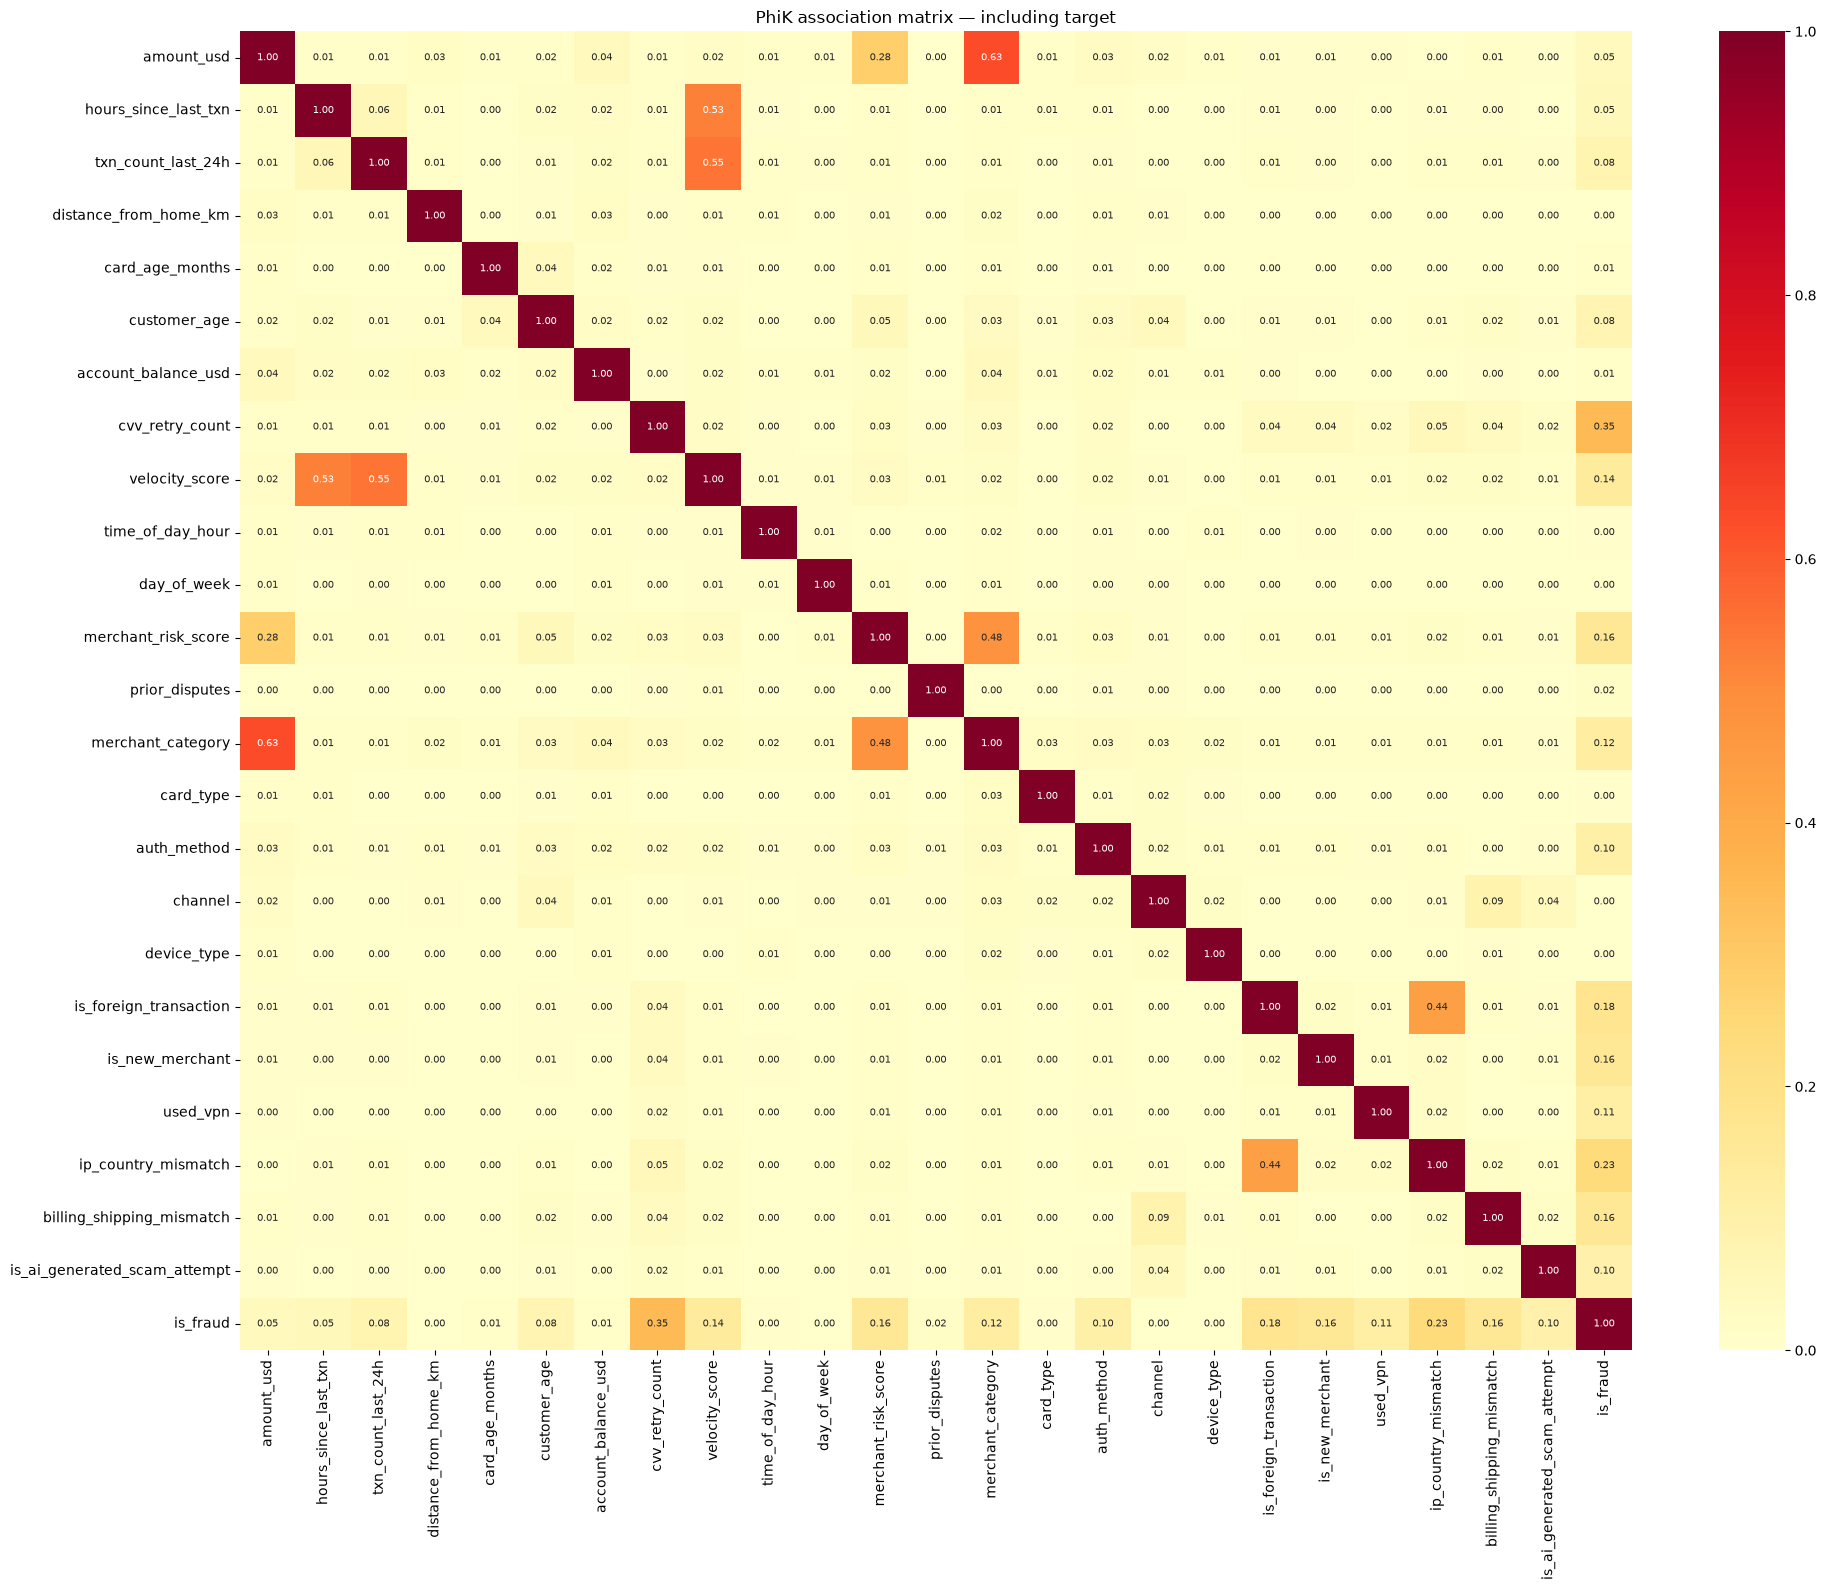

In [107]:
from phik import phik_matrix
import matplotlib.pyplot as plt
import seaborn as sns

datos_phik = data_train.drop(columns=["id"])

# Bin numerical variables only when they have many distinct values.
columnas_intervalo = [
    columna
    for columna in numericas
    if datos_phik[columna].nunique() > 10
]

matriz_phik = phik_matrix(
    datos_phik,
    interval_cols=columnas_intervalo,
    bins=10,
    quantile=True,
    noise_correction=True,
    njobs=1,
)

plt.figure(figsize=(20, 16))

sns.heatmap(
    matriz_phik,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    annot_kws={"size": 7},
)

plt.title("PhiK association matrix — including target")
plt.tight_layout()
plt.show()

In [109]:
excluir_iv = [
    "id",
    "is_fraud",
    "merchant_category",
    "cvv_retry_count",
    "ip_country_mismatch",
]

variables = [
    columna
    for columna in dict.fromkeys(categoricas + numericas)
    if columna not in excluir_iv
]

import numpy as np
import pandas as pd


def calcular_iv(grupos, target):
    datos = pd.DataFrame({"group": grupos, "target": target})

    tabla = (
        datos.groupby("group", observed=True, dropna=False)["target"]
        .agg(total="count", fraud="sum")
    )
    tabla["non_fraud"] = tabla["total"] - tabla["fraud"]

    if (tabla[["fraud", "non_fraud"]].sum() == 0).any():
        raise ValueError("IV requires both target classes.")

    smoothing = (
        0.5
        if (tabla[["fraud", "non_fraud"]] == 0).any().any()
        else 0.0
    )

    for clase in ["fraud", "non_fraud"]:
        tabla[f"dist_{clase}"] = (
            (tabla[clase] + smoothing)
            / (tabla[clase].sum() + smoothing * len(tabla))
        )

    tabla["woe"] = np.log(
        tabla["dist_non_fraud"] / tabla["dist_fraud"]
    )

    tabla["iv_contribution"] = (
        tabla["dist_non_fraud"] - tabla["dist_fraud"]
    ) * tabla["woe"]

    tabla["fraud_percentage"] = tabla["fraud"] / tabla["total"] * 100

    return tabla, smoothing


target = data_train["is_fraud"]

if target.isna().any() or set(target.unique()) != {0, 1}:
    raise ValueError(
        "Target must contain both 0 and 1, without missing values."
    )

excluir_iv = [
    "id",
    "is_fraud",
    "merchant_category",
    "cvv_retry_count",
    "ip_country_mismatch",
]

variables = [
    columna
    for columna in dict.fromkeys(categoricas + numericas)
    if columna not in excluir_iv
]

resultados = []
detalle_iv = {}

for columna in variables:
    serie = data_train[columna]

    if columna in numericas and serie.nunique() > 10:
        grupos = pd.qcut(serie, q=10, duplicates="drop")
        agrupacion = "Quantile bins"
    else:
        grupos = serie
        agrupacion = "Original values"

    tabla, smoothing = calcular_iv(grupos, target)
    detalle_iv[columna] = tabla

    resultados.append({
        "variable": columna,
        "iv": tabla["iv_contribution"].sum(),
        "groups": len(tabla),
        "min_group_count": tabla["total"].min(),
        "smoothing": smoothing,
        "grouping": agrupacion,
    })

resumen_iv = (
    pd.DataFrame(resultados)
    .sort_values("iv", ascending=False)
    .reset_index(drop=True)
)

resumen_iv

,variable,iv,groups,min_group_count,smoothing,grouping
0,merchant_risk_score,0.884425,10,69039,0.0,Quantile bins
1,velocity_score,0.688373,10,67562,0.0,Quantile bins
2,auth_method,0.588991,5,67060,0.0,Original values
3,is_new_merchant,0.420971,2,106720,0.0,Original values
4,customer_age,0.263156,10,61654,0.0,Quantile bins
5,is_foreign_transaction,0.259362,2,12098,0.0,Original values
6,txn_count_last_24h,0.208517,6,38099,0.0,Quantile bins
7,billing_shipping_mismatch,0.202227,2,9054,0.0,Original values
8,used_vpn,0.153434,2,23665,0.0,Original values
9,hours_since_last_txn,0.071840,10,68949,0.0,Quantile bins


In [111]:
from pathlib import Path

# Dataset 1: exclude the three requested predictors.
columnas_excluir = [
    "merchant_category",
    "cvv_retry_count",
    "ip_country_mismatch",
]

dataset_excluir_iv = data_train.drop(
    columns=columnas_excluir
).copy()

# Rank the remaining predictors by descending IV.
ranking_iv = (
    resumen_iv.loc[
        ~resumen_iv["variable"].isin(
            columnas_excluir + ["id", "is_fraud"]
        )
    ]
    .sort_values("iv", ascending=False)
    .reset_index(drop=True)
)

# Dataset 2: keep is_new_merchant and all predictors below it.
variable_corte = "is_new_merchant"

posiciones = ranking_iv.index[
    ranking_iv["variable"].eq(variable_corte)
]

if len(posiciones) != 1:
    raise ValueError("The cutoff variable must appear exactly once.")

variables_conservar = ranking_iv.loc[
    posiciones[0]:, "variable"
].tolist()

dataset_mega_excluir_iv = data_train[
    ["id"] + variables_conservar + ["is_fraud"]
].copy()

# Export both datasets without adding an index column.
carpeta_salida = Path("../data")

if not carpeta_salida.is_dir():
    raise FileNotFoundError("Expected output folder ../data was not found.")

dataset_excluir_iv.to_csv(
    carpeta_salida / "train_excluir_iv.csv",
    index=False,
)

dataset_mega_excluir_iv.to_csv(
    carpeta_salida / "train_mega_excluir_iv.csv",
    index=False,
)

print("Dataset 1:", dataset_excluir_iv.shape)
print("Dataset 2:", dataset_mega_excluir_iv.shape)

Dataset 1: (699960, 23)
Dataset 2: (699960, 20)


In [112]:
print("Dataset 1:", dataset_excluir_iv.columns.tolist())
print("Dataset 2:", dataset_mega_excluir_iv.columns.tolist())

Dataset 1: ['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'is_fraud']
Dataset 2: ['id', 'is_new_merchant', 'customer_age', 'is_foreign_transaction', 'txn_count_last_24h', 'billing_shipping_mismatch', 'used_vpn', 'hours_since_last_txn', 'amount_usd', 'is_ai_generated_scam_attempt', 'prior_disputes', 'account_balance_usd', 'card_age_months', 'time_of_day_hour', 'card_type', 'channel', 'distance_from_home_km', 'day_of_week', 'device_type', 'is_fraud']
